# Bragg diagnostics

A static fiber with point reflectors and frozen Rayleigh scattering.
Only the Bragg mesh changes. Install PyRayleigh, NumPy and Matplotlib;
the optional JAX backend also needs the JAX extra.

In [1]:
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from pyrayleigh import (BraggGrating, Fiber, FiberState, Field, FieldTerm, GuideOptics,
    Probe, Section, SpatialProfile, compare_responses, compute_response,
    compute_response_diagnostics, lossless_reflector, response_convergence_report)
from pyrayleigh.constants import SPEED_OF_LIGHT

backend = 'numpy'
if backend == 'jax':
    import jax
    import jax.numpy as xp
    jax.config.update('jax_enable_x64', True)
else:
    import array_api_compat.numpy as xp

In [2]:
def make_fiber(xp):
    frequency = SPEED_OF_LIGHT/1550e-9
    guide = GuideOptics(frequency+2e9, 1.4682, 1.474, -2.1e-26)
    apodization = SpatialProfile([.005, .01, .015], xp.asarray([0., 1., 0.]))
    grating = BraggGrating(.005, .01, 1550e-9, 100., segment_length=.0025,
        apodization=apodization)
    fiber = Fiber('bragg-example', .02, 293.15, frequency-5e9, frequency+5e9,
        (Section(0., .02, guide, .1, .01),), gratings=(grating,),
        elements=(lossless_reflector(.002, .02, -.2, xp=xp),
            lossless_reflector(.01, .05, .3, xp=xp)))
    return fiber.with_rayleigh(161, cell_length=.005, xp=xp)


def fiber_state(fiber, strain, xp):
    positions = [0., fiber.length]
    axial = SpatialProfile(positions, xp.stack((strain, strain)))
    temperature = SpatialProfile(positions, xp.asarray([2., 2.]))
    return FiberState(axial_strain=Field((FieldTerm(axial),)),
        temperature_change=Field((FieldTerm(temperature),)))


def run(xp):
    fiber = make_fiber(xp)
    frequency = SPEED_OF_LIGHT/1550e-9
    probe = Probe(frequency+xp.linspace(-2e9, 2e9, 17, dtype=xp.float64))
    strain = xp.asarray(1e-6, dtype=xp.float64)
    fibers, diagnostics = [], []
    for width in (.0025, .00125, .000625):
        grating = replace(fiber.gratings[0], segment_length=width)
        model = replace(fiber, gratings=(grating,))
        fibers.append(model)
        diagnostics.append(compute_response_diagnostics(model, probe, fiber_state(model, strain, xp),
            loss_convention='background', xp=xp))
    return fibers, probe, strain, diagnostics

In [3]:
fibers, probe, strain, diagnostics = run(xp)
fine = diagnostics[-1]
unloaded = compute_response(fibers[-1], probe, fiber_state(fibers[-1], xp.asarray(0.), xp),
    method='exact', loss_convention='background', xp=xp)
change = compare_responses(fine.total, unloaded, xp=xp)
multipath = compare_responses(fine.total, fine.direct, xp=xp)
convergence = response_convergence_report(*(result.total for result in diagnostics), xp=xp)
print('Backend:', fine.metadata['backend'])
print('Frozen Rayleigh cells:', fibers[0].rayleigh.cell_count)
print('Uniform strain:', float(strain), '; temperature change: 2 K in both states')
print('Relative reflected-field change:', float(change['reflection']['relative_l2']))
print('||exact-direct|| / ||direct||, reflection:', float(multipath['reflection']['relative_l2']))
print('Observed Bragg mesh orders:',
    {port: float(value) for port, value in convergence['observed_order'].items()})

Backend: numpy
Frozen Rayleigh cells: 4
Uniform strain: 1e-06 ; temperature change: 2 K in both states
Relative reflected-field change: 0.08775178384999392
||exact-direct|| / ||direct||, reflection: 0.08570512971873974
Observed Bragg mesh orders: {'reflection': 1.997149099416145, 'transmission': 1.9887098259779692}


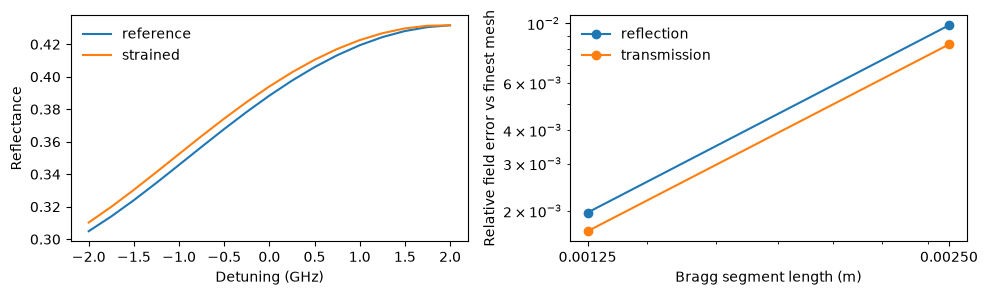

In [4]:
detuning = (np.asarray(probe.frequency)-SPEED_OF_LIGHT/1550e-9)/1e9
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(detuning, abs(np.asarray(unloaded.reflection))**2, label='reference')
ax[0].plot(detuning, abs(np.asarray(fine.total.reflection))**2, label='strained')
ax[0].set(xlabel='Detuning (GHz)', ylabel='Reflectance')
widths = [fiber.gratings[0].segment_length for fiber in fibers[:-1]]
for port in ('reflection', 'transmission'):
    errors = [float(compare_responses(result.total, fine.total, xp=xp)[port]['relative_l2'])
        for result in diagnostics[:-1]]
    ax[1].loglog(widths, errors, 'o-', label=port)
ax[1].set(xlabel='Bragg segment length (m)', ylabel='Relative field error vs finest mesh')
ax[1].set_xticks(widths, [f'{width:.5f}' for width in widths])
ax[1].tick_params(axis='x', which='minor', labelbottom=False)
for axis in ax:
    axis.legend(frameon=False)
fig.tight_layout()
plt.show()

In [5]:
if backend == 'jax':
    def mean_reflectance(value):
        result = compute_response(fibers[-1], probe, fiber_state(fibers[-1], value, xp),
            method='exact', loss_convention='background', xp=xp)
        return xp.mean(xp.real(result.reflection*xp.conj(result.reflection)))
    derivative = jax.jit(jax.grad(mean_reflectance))(strain)
    print('d(mean reflectance)/d(strain), fixed temperature:', float(derivative))